# 第 03 关：市场 β 能否解释平均收益差异？

**本关要回答的问题：** 第 02 关发现小盘股、价值股的平均收益更高。是不是因为它们的市场 β 更高，承担了更多市场风险？

### 检验思路：时间序列回归
对每个测试组合 $i$，用月度数据做回归：

$$
R_{i,t}-R_{f,t}=\alpha_i+\beta_i(R_{M,t}-R_{f,t})+\varepsilon_{i,t}.
$$

- $\beta_i$：组合对市场的敏感度（第 01 关已介绍）；
- $\alpha_i$：截距，单位 %/月；
- $\varepsilon_{i,t}$：残差，即当月市场解释不了的部分。

**为什么检验的焦点是截距 α？** 把上式在样本期内取平均，OLS 残差的平均值恰好为零，于是

$$
\underbrace{\overline{R_i-R_f}}_{\text{实际平均超额收益}}=\alpha_i+\underbrace{\beta_i\,\overline{R_M-R_f}}_{\text{CAPM 预测的平均超额收益}}.
$$

所以 α = 实际平均超额收益 − CAPM 预测的平均超额收益，也就是模型的**定价误差**。CAPM 成立时，所有组合的 α 都应该为零。正 α 表示这个组合的平均收益比它的 β "应得"的更高。

这里因子和组合收益用的是**同一个月**的数据：回归检验的是平均收益之间的关系，而不是用本月的信息预测下个月。

本关对照 FF1993 的 **Table 4**（β 与 R²）和 **Table 9a(ii)**（α）。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/course.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from course import (load_raw, load_returns, raw_path, catalog, manifest, style,
                    build_ff3, build_ff5, heatmap25, save_table, paper_note)
from analysis import fit_models, grs_test, model_summary
style()
print('项目目录：', ROOT)

项目目录： E:\Eth data\asset_pricing_quest


In [2]:
display(Markdown(paper_note('ff1993')))

**论文对照：** [Fama & French (1993), Common risk factors in the returns on stocks and bonds](../papers/ff1993_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 先完整跑一个组合的回归
以"规模最小、B/M 最低"的组合 `SMALL LoBM` 为例。`sm.add_constant` 给解释变量加上一列常数 1，常数的系数（表中 `const` 一行）就是 α，`Mkt-RF` 一行是 β。系数以小数表示：const = −0.0026 即 α = −0.26%/月。

表中两种 t 值的区别：`t_OLS` 使用普通标准误，假设残差各月独立、波动大小不变；`t_HAC6` 使用第 02 关介绍的 HAC 标准误，允许异方差和 6 个月以内的前后相关。两者的系数完全相同，只是对估计误差的度量不同。

In [3]:
import statsmodels.api as sm
ff = load_returns('ff3','1963-07','1991-12')
p = load_returns('bm25','1963-07','1991-12')
y = p.sub(ff.RF,axis=0)
market = ff[['Mkt-RF']]
asset = y.columns[0]
fit = sm.OLS(y[asset],sm.add_constant(market)).fit()
robust = fit.get_robustcov_results(cov_type='HAC',maxlags=6)
display(pd.DataFrame({'coefficient':fit.params,'t_OLS':fit.tvalues,'t_HAC6':robust.tvalues}))

,coefficient,t_OLS,t_HAC6
const,-0.0026,-1.1414,-0.9098
Mkt-RF,1.4168,28.1300,21.6110


**读数：** 这个组合的 β 约 1.42，对市场相当敏感；α 约 −0.26%/月，但 t 值只有 −1 左右，不显著。单看这一个组合，CAPM 的定价误差还在估计误差的范围之内。

## 2. 对全部 25 个组合运行同样的回归
`fit_models` 对每个组合跑一遍上面的回归，返回结果表和残差矩阵（残差在第 05 关做联合检验时要用）。

表中各列：`alpha_pct_month` 是截距 α（%/月）；`beta_Mkt-RF` 是市场 β；`t_alpha_ols`、`t_alpha_hac` 是 α 的普通 t 值和 HAC t 值；`adj_r2` 是**调整 R²**。R² 衡量市场解释了组合月度波动的多大比例；调整 R² 再扣除"多加解释变量就会机械提高 R²"的部分。FF1993 报告的是调整 R²。

,alpha_pct_month,beta_Mkt-RF,t_alpha_ols,t_alpha_hac,adj_r2
asset,,,,,
SMALL LoBM,-0.2646,1.4168,-1.1414,-0.9071,0.6986
ME1 BM2,0.1532,1.2416,0.7609,0.6588,0.7023
ME1 BM3,0.2697,1.1537,1.4582,1.2728,0.7071
ME1 BM4,0.4248,1.0717,2.3548,2.1431,0.6865
SMALL HiBM,0.5381,1.0997,2.6392,2.3604,0.6435
ME2 BM1,-0.1916,1.4270,-1.0950,-0.9180,0.8051
ME2 BM2,0.1382,1.2304,0.9100,0.8263,0.8030
ME2 BM3,0.3790,1.1117,2.6412,2.6198,0.7885
ME2 BM4,0.4762,1.0315,3.5151,3.1621,0.7826


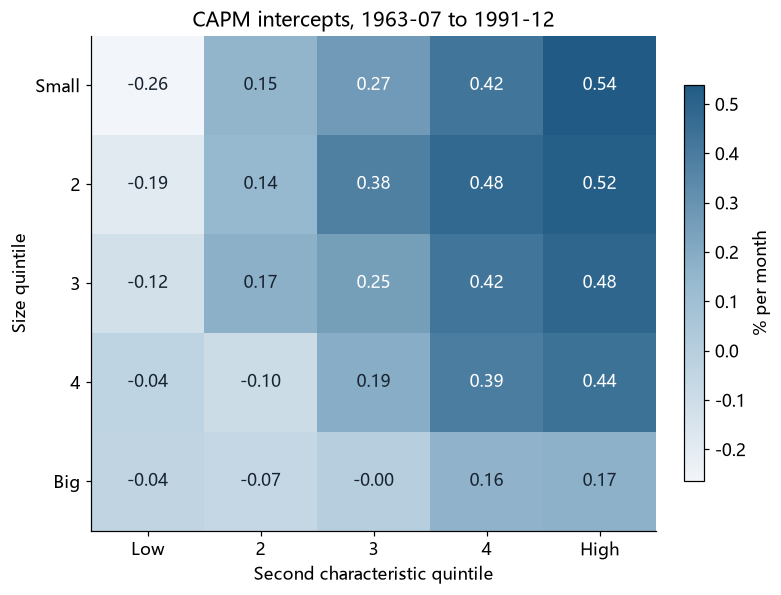

WindowsPath('E:/Eth data/asset_pricing_quest/results/03_ff1993_table4_capm.csv')

In [4]:
table, residuals = fit_models(y,market)
display(table[['alpha_pct_month','beta_Mkt-RF','t_alpha_ols','t_alpha_hac','adj_r2']])
heatmap25(table.alpha_pct_month,'CAPM intercepts, 1963-07 to 1991-12','% per month')
plt.show()
save_table(table,'03_ff1993_table4_capm')

**怎么读：**
- **先看 β**：25 个组合的 β 都在 0.84–1.43 之间，差别不大；而且低 B/M 组合的 β 反而更高。也就是说，β 的排列方向与第 02 关的平均收益正好相反。
- **再看 α 热力图**：α 从左到右明显上升。前四个规模组中，最高 B/M 组合的 α 约 0.44–0.54%/月，HAC t 值都超过 2。

CAPM 系统性地低估了价值股的收益、高估了成长股的收益。

## 3. 用"预测 vs 实际"图看 α
前面推导过：实际平均超额收益 = α + β × 市场平均超额收益。代码先用 `assert` 验证这个等式，再把每个组合画成一个点：横轴是 CAPM 预测的平均超额收益（β × 市场均值），纵轴是实际平均超额收益。点落在 45° 虚线上表示 α = 0；在线上方表示实际收益高于 CAPM 的预测（正 α）。

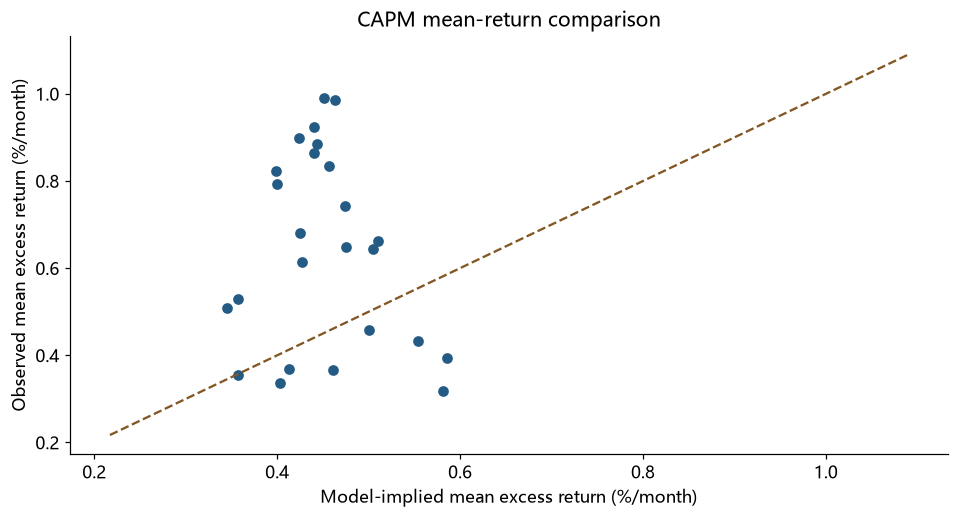

25 个组合的平均绝对 α 为 **0.257 个百分点/月**（约 3.1 个百分点/年）。CAPM 预测的平均超额收益只在 0.34%–0.59%/月之间变化，实际平均超额收益却分布在 0.32%–0.99%/月：点云几乎是竖着排列的，远离 45° 线。β 的差异太小，撑不起这么大的平均收益差异。

In [5]:
model_mean = table['beta_Mkt-RF'] * market['Mkt-RF'].mean()   # CAPM 预测：β × 市场平均超额收益
observed_mean = y.mean()                                        # 实际平均超额收益
assert np.allclose(observed_mean - model_mean, table.alpha)     # 两者之差恰好是 α
fig, ax = plt.subplots(layout='constrained')
ax.scatter(model_mean*100,observed_mean*100,color='#245b85')
lim = [min(model_mean.min(),observed_mean.min())*100-.1, max(model_mean.max(),observed_mean.max())*100+.1]
ax.plot(lim,lim,color='#825723',linestyle='--')
ax.set(xlabel='Model-implied mean excess return (%/month)',ylabel='Observed mean excess return (%/month)',title='CAPM mean-return comparison')
plt.show()
mean_abs_alpha = table.alpha_pct_month.abs().mean()
display(Markdown(
    f'25 个组合的平均绝对 α 为 **{mean_abs_alpha:.3f} 个百分点/月**（约 {mean_abs_alpha*12:.1f} 个百分点/年）。'
    f'CAPM 预测的平均超额收益只在 {model_mean.min()*100:.2f}%–{model_mean.max()*100:.2f}%/月之间变化，'
    f'实际平均超额收益却分布在 {observed_mean.min()*100:.2f}%–{observed_mean.max()*100:.2f}%/月：'
    '点云几乎是竖着排列的，远离 45° 线。β 的差异太小，撑不起这么大的平均收益差异。'))

## 4. 结论能推到哪里
- **CAPM 解释不了 B/M 排序带来的平均收益差异**：价值组合的 α 显著为正，而且 β 的差异太小、方向也不对。
- **被检验的是"CAPM + 市场代理"这一组合**：理论中的市场组合包含所有风险资产（股票、债券、房地产，甚至人力资本），实证中只能用美国股票市场指数代替。拒绝 CAPM 既可能因为理论本身不对，也可能因为代理不够好，这一点称为 Roll 批判（Roll 1977）。
- **逐个看 t 值还不够**：25 个组合的残差高度相关，25 次检验不是相互独立的。第 05 关用 GRS 检验把 25 个 α 合在一起检验。

## 5. 与原文对照
原文把同一组回归的结果分在两张表：β 和调整 R² 在 **Table 4**（PDF 第 18 页），α 在 **Table 9a(ii)**（PDF 第 34 页）。下面以 `SMALL LoBM` 为例逐项对照：`原表` 是表号，`指标` 是对应的列，`当前减原文` 是重算值减原文值。小的差异来自数据修订和四舍五入。

In [6]:
import json
anchors = json.loads((ROOT/'papers/paper_map.json').read_text(encoding='utf-8'))['numeric_anchors']

rows = []
for a in anchors:
    if a['paper']=='ff1993' and a.get('model')=='CAPM':
        field = {'market_beta':'beta_Mkt-RF','adjusted_r_squared':'adj_r2','alpha':'alpha_pct_month'}[a['metric']]
        current = table.loc[a['key'],field]
        rows.append({'原表':a['table'],'指标':field,'原文':a['paper_value'],'当前快照':current,'当前减原文':current-a['paper_value']})
display(pd.DataFrame(rows))

,原表,指标,原文,当前快照,当前减原文
0,4,beta_Mkt-RF,1.40,1.4168,0.0168
1,4,adj_r2,0.67,0.6986,0.0286
2,9a,alpha_pct_month,-0.22,-0.2646,-0.0446


## Boss 作答区

从结果中挑一个你认为需要进一步解释的组合。写出证据、你的经济假说，以及你希望三因子模型改善的具体指标。

**我的回答：**

（由你填写；本课程未预填答案。）